# **1. 멀티 모달**
- 사람은 사진만 보거나 글만 읽지 않음 > 눈으로 보고, 말을 듣고, 글을 읽고, 상황을 함께 해석함
- 멀티모달도 위와 비슷하게 서로 다른 형태의 정보를 함께 다룸
  - 이미지: 픽셀, 사물, 색, 위치, 장면
  - 텍스트: 단어, 문장, 의미, 질문
  - 오디오: 음성, 소리, 음악
  - 비디오: 이미지의 시간적 변화 + 경우에 따라 오디오 함께

### 1. Multimodal Learning
> Multimodal Learning은 서로 다른 여러 모달리티의 데이터를 함께 학습하는 방식입니다. 예를 들어 이미지와 텍스트를 동시에 입력으로 받아 장면을 설명하거나, 영상과 음성을 함께 활용해 감정을 인식하는 모델이 이에 해당합니다. 각 모달리티가 가진 상호보완적인 정보를 결합함으로써 단일 모달리티보다 더 풍부한 표현과 높은 성능을 기대할 수 있습니다. 최근에는 비전과 언어를 결합한 모델들이 대표적인 성공 사례로 주목받고 있습니다.

## 2. CLIP
CLIP은 이미지와 텍스트를 같은 의미 공간으로 정렬하기 위해 대비 학습(contrastive learning)을 사용하는 대표적인 Pretrained Vision–Language 모델입니다. 이미지 인코더와 텍스트 인코더를 각각 학습시킨 뒤, 올바른 이미지–텍스트 쌍은 임베딩 공간에서 가깝게, 관련 없는 쌍은 멀어지도록 학습함으로써 두 모달리티 간 의미적 대응 관계를 형성합니다. 이 구조 덕분에 별도의 태스크별 학습 없이도 텍스트로 정의한 클래스 설명만으로 이미지를 분류하는 zero-shot 분류가 가능하며, 이미지–텍스트 검색(Text-to-Image, Image-to-Text Retrieval)에 특히 강점을 보입니다. 다만 생성 능력은 없고, 주로 “이해와 정렬”에 초점이 맞춰진 모델이라는 특징을 가집니다. [논문](https://arxiv.org/pdf/2103.00020)


### 표현 정렬과 생성의 차이
- Dual encoder(CLIP): 이미지와 문장을 독립적으로 벡터화하고 유사도를 비교. 빠른 검색/zero-shot 분류에 적합.
- Encoder-decoder(BLIP): 이미지 특징을 참고해 문장을 토큰 단위로 생성
- Grounded detection(Grounding DINO): 텍스트 표현을 조건으로 이미지 속 위치(박스)를 찾음
- VLM/멀티모달 LLM: 비전 인코더와 언어 모델을 연결하여 이미지 기반 질의응답/추론/대화를 수행할 수 있음. 모델별 성능과 지원 모달리티는 다름
- 인코더: 원본 데이터를 모델이 계산하기 좋은 숫자 특징으로 바꾸는 부분
  - 예) 이미지 인코더는 사진을, 텍스트 인코더는 문장을 받아 벡터로 바꿈
- 임베딩: 데이터의 의미를 숫자 배열(벡터)로 표현한 것. 비슷한 의미를 가진 데이터가 한 방향에 놓이도록 학습함
- 프로젝션: 이미지 인코더와 텍스트 인코더가 만든 서로 다른 특징을 같은 차원의 공통 공간으로 옮기는 변환
- 유사도: 두 벡터가 의미적으로 얼마나 가까운지 나타내는 값

### 대비 학습(contrastive learning)

| | 문장1 | 문장2 | 문장3 | 문장4 |
|---|---|---|---|---|
| 이미지1 | 높음 | 낮음 | 낮음 | 낮음 |
| 이미지2 | 낮음 | 높음 | 낮음 | 낮음 |
| 이미지3 | 낮음 | 낮음 | 높음 | 낮음 |
| 이미지4 | 낮음 | 낮음 | 낮음 | 높음 |

<br>

> 정답 쌍은 대각선. 학습은 대각선 점수는 높이고, 나머지를 낮추는 방향으로 진행. CLIP은 이미지 > 텍스트 검색, 이미지 검색을 모두 수행할 수 있게 학습

```
고양이 사진 <> "a photo of a cat" (가깝게)
고양이 사진 <> "a photo of a banana" (멀게)
고양이 사진 <> "a photo of a TV" (멀게)
```

매우 많은 이미지-텍스트 쌍으로 학습을 반복하면 모델은 단순 클래스 번호가 아니라 시각적 특징과 언어 의미의 관계를 학습하게 됨

### Zero-Shot 분류
1. 후보 클래스 이름을 문장으로 만듦 예) "a photo of a cat"
2. 후보 문장들의 텍스트 임베딩을 만듦
3. 입력 이미지 임베딩과 각 텍스트 임베딩의 유사도를 비교함
4. 가장 유사한 텍스트를 예측 클래스로 사용함

> Shot은 새로운 작업에서 제공하는 학습 예제 수.

In [2]:
import random
import io
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from datasets import load_dataset
from transformers import AutoProcessor, CLIPModel

In [3]:
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


$S_{ij}=v_i^\top t_j/\tau$

### CLIP 학습 원리
- 배치 대조 손실
    - $S_{ij}=v_i^\top t_j/\tau$
    - 이미지 임베딩($v_i$)와 텍스트 임베딩 $t_j$를 L2 정규화한 뒤, 유사도 행렬 $S_{ij}를 만듦
    - $\tau$는 temperature이며 구현에서는 학습 가능한 logit_scale을 사용
    - 정답 쌍이 대각선에 오도록 이미지 > 텍스트와 텍스트 > 이미지 교차 엔트로피를 평균해 학습함

> softmax로 얻은 후보별 점수는 주어진 후보 문장들 사이의 상대적 값이며, 현실 세계의 절대적인 정답 확률로 해석하면 안됨

In [4]:
MODEL_ID = "openai/clip-vit-base-patch32"
DATASET_ID = "clip-benchmark/wds_imagenetv2"
SAMPLE_SIZE = 10

# AutoProcessor: 이미지 리사이즈/정규화와 텍스트 토큰화를 모델에 맞게 처리하도록 객체를 생성
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(MODEL_ID).to(DEVICE)
model.eval()
print("CLIP projection dim: ", model.config.projection_dim)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP projection dim:  512


In [5]:
dataset = load_dataset(DATASET_ID, split="test")
subset = dataset.shuffle(seed=SEED).select(range(SAMPLE_SIZE))
print(subset)
print("columns: ", subset.column_names)

Dataset({
    features: ['__key__', '__url__', 'cls', 'webp'],
    num_rows: 10
})
columns:  ['__key__', '__url__', 'cls', 'webp']


In [6]:
def to_pil(x):
    if isinstance(x, Image.Image):
        return x.convert("RGB")
    if isinstance(x, dict) and x.get("bytes") is not None:
        return Image.open(io.BytesIO(x["bytes"])).convert("RGB")
    if isinstance(x, str):
        return Image.open(x).convert("RGB")
    raise TypeError(f"지원하지 않는 이미지 타입: {type(x)}")

image_col = "webp" if "webp" in subset.column_names else "image"
label_col = "cls" if "cls" in subset.column_names else "label"

images = [to_pil(x) for x in subset[image_col]]
labels = [int(x) for x in subset[label_col]]
print(labels)

[256, 661, 452, 448, 231, 528, 208, 985, 482, 475]


In [7]:
try:
    from torchvision.models import ResNet50_Weights
    imagenet_names = ResNet50_Weights.DEFAULT.meta["categories"]
except Exception as e:
    raise RuntimeError(
        "ImageNet 클래스 이름을 불러오지 못했습니다. torchvision을 설치하거나 기존 classnames.txt를 사용하세요."
    ) from e

In [8]:
imagenet_names

['tench',
 'goldfish',
 'great white shark',
 'tiger shark',
 'hammerhead',
 'electric ray',
 'stingray',
 'cock',
 'hen',
 'ostrich',
 'brambling',
 'goldfinch',
 'house finch',
 'junco',
 'indigo bunting',
 'robin',
 'bulbul',
 'jay',
 'magpie',
 'chickadee',
 'water ouzel',
 'kite',
 'bald eagle',
 'vulture',
 'great grey owl',
 'European fire salamander',
 'common newt',
 'eft',
 'spotted salamander',
 'axolotl',
 'bullfrog',
 'tree frog',
 'tailed frog',
 'loggerhead',
 'leatherback turtle',
 'mud turtle',
 'terrapin',
 'box turtle',
 'banded gecko',
 'common iguana',
 'American chameleon',
 'whiptail',
 'agama',
 'frilled lizard',
 'alligator lizard',
 'Gila monster',
 'green lizard',
 'African chameleon',
 'Komodo dragon',
 'African crocodile',
 'American alligator',
 'triceratops',
 'thunder snake',
 'ringneck snake',
 'hognose snake',
 'green snake',
 'king snake',
 'garter snake',
 'water snake',
 'vine snake',
 'night snake',
 'boa constrictor',
 'rock python',
 'Indian cobr

In [9]:
label_names = [imagenet_names[i] for i in labels]
label_names

['Newfoundland',
 'Model T',
 'bonnet',
 'birdhouse',
 'collie',
 'dial telephone',
 'Labrador retriever',
 'daisy',
 'cassette player',
 'car mirror']

In [10]:
text_prompts = [f"a photo of a {name}" for name in label_names]
text_prompts

['a photo of a Newfoundland',
 'a photo of a Model T',
 'a photo of a bonnet',
 'a photo of a birdhouse',
 'a photo of a collie',
 'a photo of a dial telephone',
 'a photo of a Labrador retriever',
 'a photo of a daisy',
 'a photo of a cassette player',
 'a photo of a car mirror']

In [11]:
for i, (name, prompt) in enumerate(zip(label_names, text_prompts)):
    print(f'{i:02d} | {name:25s} | {prompt}')

00 | Newfoundland              | a photo of a Newfoundland
01 | Model T                   | a photo of a Model T
02 | bonnet                    | a photo of a bonnet
03 | birdhouse                 | a photo of a birdhouse
04 | collie                    | a photo of a collie
05 | dial telephone            | a photo of a dial telephone
06 | Labrador retriever        | a photo of a Labrador retriever
07 | daisy                     | a photo of a daisy
08 | cassette player           | a photo of a cassette player
09 | car mirror                | a photo of a car mirror


In [12]:
# processor: 모델은 PIL 이미지나 문자열을 그대로 계산하지 못함. 입력을 모델 형식으로 바꿔주는 전처리 담당자.
# 이미지 > resize > pixel 변환 > normalize > 모델 입력 Tensor
# 문장 > tokenize > token id 변환 > 모델 입력 Tensor
inputs = processor( 
  images=images, 
  text=text_prompts, 
  padding=True, 
  return_tensors="pt" 
).to(DEVICE) 

In [13]:
with torch.inference_mode():
  outputs = model(**inputs)

In [14]:
image_features = outputs.image_embeds
text_features = outputs.text_embeds

print("image_features type: ", type(image_features))
print("text_features type: ", type(text_features))
print("image_features shape: ", image_features.shape)
print("text_features shape: ", text_features.shape)

image_features type:  <class 'torch.Tensor'>
text_features type:  <class 'torch.Tensor'>
image_features shape:  torch.Size([10, 512])
text_features shape:  torch.Size([10, 512])


### L2정규화 코사인 유사도
벡터의 길이를 1로 만들면 두 벡터의 내적은 코사인 유사도가 됨

```python
x = torch.tensor([[3.0, 4.0]])
result = F.normalize(x, p=2, dim=1)

3^2 + 4^2 = 25 > 5

3/5, 4/5 = [0.6, 0.8]

0.6^2 + 0.8^2 = 1
```

- 1에 가까울수록 방향이 비슷함 > 의미적으로 더 잘 맞음
- 0 부근 > 관련성이 약함
- 음수 > 방향이 반대인 경향

### L2정규화
벡터의 크기 자체보다 방향, 의미적 방향을 비교하기 위해 사용
- F.normalize(..., p=2): 각 벡터의 길이를 1로 만듦. 두 단위의 내적이 코사인 유사도와 같아짐

- F.normalize(..., p=2): 각 벡터의 길이를 1로 만듦. 두 단위의 내적이 코사인 유사도와 같아짐

p=1 L1 노름: 절댓값을 더함
p=2 L2 노름: 제곱해서 더한 뒤 제곱근
p=3 L3 노름: 세제곱해서 더한 뒤 세제곱근


In [15]:
import torch.nn.functional as F

image_features = F.normalize(image_features, p=2, dim=-1)
text_features = F.normalize(text_features, p=2, dim=-1)

similarity = image_features @ text_features.T
print("similarity tensor shape: ", similarity.shape)
print(torch.round(similarity.cpu() * 1000) / 1000)
similarity_np = similarity.cpu().numpy()

similarity tensor shape:  torch.Size([10, 10])
tensor([[0.2680, 0.1930, 0.1960, 0.1820, 0.2430, 0.1910, 0.2450, 0.1730, 0.1650,
         0.1600],
        [0.1890, 0.3110, 0.2300, 0.1650, 0.2040, 0.2110, 0.2150, 0.1840, 0.1680,
         0.2200],
        [0.1800, 0.1870, 0.2460, 0.2070, 0.1920, 0.1800, 0.2080, 0.2310, 0.1660,
         0.1860],
        [0.2140, 0.2000, 0.2940, 0.3100, 0.2090, 0.2220, 0.2290, 0.2310, 0.1760,
         0.1960],
        [0.2310, 0.2080, 0.2100, 0.1690, 0.2780, 0.1840, 0.2280, 0.2280, 0.1800,
         0.1720],
        [0.1890, 0.2070, 0.2090, 0.1910, 0.1860, 0.3240, 0.1940, 0.2040, 0.2150,
         0.1970],
        [0.2140, 0.1800, 0.2090, 0.1930, 0.2440, 0.1920, 0.2390, 0.1940, 0.1570,
         0.1880],
        [0.1940, 0.1980, 0.2550, 0.2180, 0.2280, 0.2070, 0.2020, 0.3230, 0.1880,
         0.2070],
        [0.1550, 0.2190, 0.2320, 0.1910, 0.1870, 0.2450, 0.1720, 0.1950, 0.2680,
         0.2070],
        [0.1940, 0.1920, 0.2250, 0.1940, 0.2020, 0.2030, 0.212

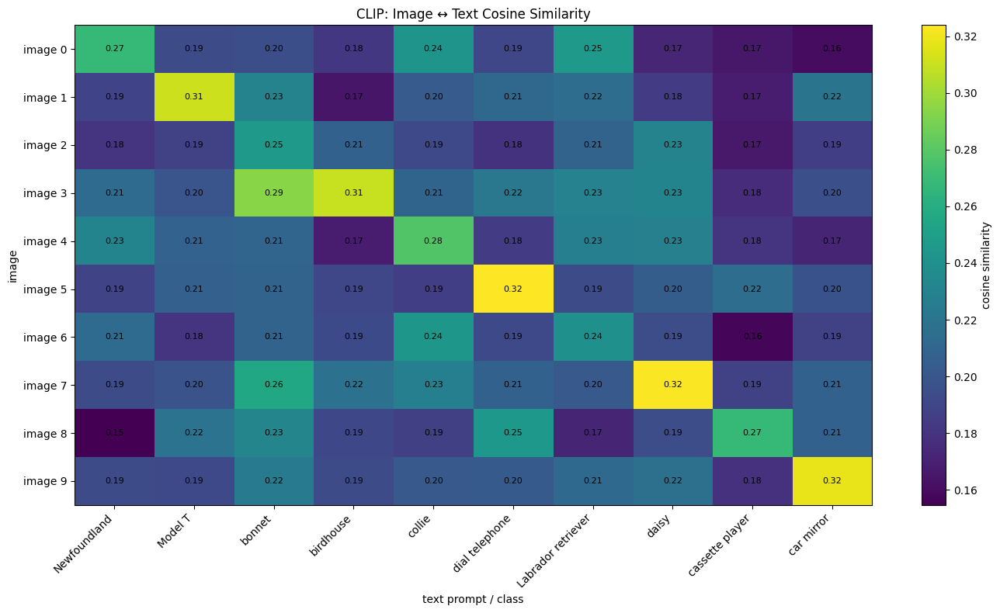

In [16]:
fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(similarity_np, aspect="auto")
fig.colorbar(im, ax=ax, label="cosine similarity")

ax.set_xticks(range(len(images)))
ax.set_xticklabels(label_names, rotation=45, ha="right")
ax.set_yticks(range(len(images)))
ax.set_yticklabels([f"image {i}" for i in range(len(images))])

ax.set_xlabel("text prompt / class")
ax.set_ylabel("image")
ax.set_title("CLIP: Image ↔ Text Cosine Similarity")

for i in range(len(images)):
    for j in range(len(images)):
        ax.text(
            j, i,
            f"{similarity_np[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

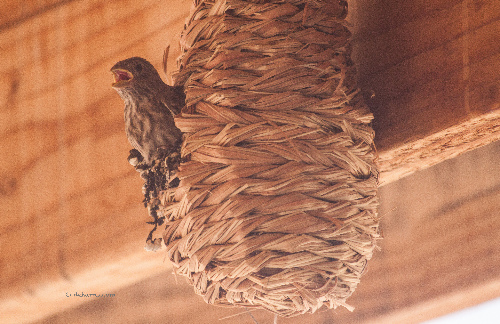

In [17]:
images[3]

# **3. DINO**
AI 분야에서 DINO라는 이름은 서로 다른 유명 연구에 쓰임

1. DINO(Self-Distillation with No Labels): Meta 계열의 자기지도 학습 비전 표현 학습 연구. DINOv2, DINOv3 계열
   - DETR: Transformer와 object query를 이용해 객체 탐지를 set prediction 문제로 바꿈. anchor 설계와 NMS 중심의 전통적인 파이프라인을 크게 단순화[[논문](https://arxiv.org/pdf/2005.12872)]
      - object query: Decoder에 들어가는 학습 가능한 객체 슬롯. 예) 100개의 query가 있다면 각 query는 이미지 특징을 보면서 "내가 찾고자하는 객체가 있는가? 있다면 어떤 클래스이고 박스는 어디에 있나?"를 학습
   - DETR 계열의 느린 수렴과 query 학습 문제를 개선하기 위해 denoising training, 더 좋은 query/reference 설계 등 사용
  - denoising training: 정답 label/box에 일부 노이즈를 넣은 query를 추가하고, 모델이 원래 정답을 복원하도록 학습
   - Grounding DINO: DINO 계열 detector에 언어 조건을 결합.
      - DETR: 이미지 > 객체가 어디에 있는지 찾음
      - DINO: 이미지 > DETR보다 더 안정적이고 효율적으로 객체를 찾음
      - Grounding DINO > 이미지 + 텍스트 > 이 텍스트가 가리키는 객체가 어디에 있는지 찾음
         - 예) a cat. a remote control. 을 넣게되면 모델은 클래스 번호만 출력하는 것이 아니라 텍스트 표현과 관련 있는 이미지 영역을 찾아 박스로 반환



# **3. DINO**
AI 분야에서 DINO라는 이름은 서로 다른 유명 연구에 쓰임
1. DINO(Self-Distillation with No Labels): Meta 계열의 자기지도 학습 비전 표현 학습 연구. DINOv2, DINOv3 계열
2. DINO(DETR with Improved DeNoising Anchor Boxes): DETR 계열 객체 탐지 모델 [[논문](https://arxiv.org/pdf/2203.03605)]
    - DETR: Transformer와 object query를 이용해 객체 탐지를 set prediction 문제로 바꿈. anchor 설계와 NMS 중심의 전통적인 파이프라인을 크게 단순화[[논문](https://arxiv.org/pdf/2005.12872)]
        - object query: Decoder에 들어가는 학습 가능한 객체 슬롯. 예) 100개의 query가 있다면 각 query는 이미지 특징을 보면서 "내가 찾고자하는 객체가 있는가? 있다면 어떤 클래스이고 박스는 어디에 있나?를 학습
    - DETR 계열의 느림 수렴과 query 학습 문제를 개선하기 위해 denoising training, 더 좋은 query/reference 설계 등 사용
        - denoising training: 정답 label/box에 일부 노이즈를 넣은 query를 추가하고, 모델이 원래 정답을 복원하도록 학습
    - Grounding DINO: DINO 계열 detector에 언어 조건을 결합.
        - DETR: 이미지 > 객체가 어디에 있는지 찾음
        - DINO: 이미지 > DETR보다 더 안정적이고 효율적으로 객체를 찾음
        - Grounding DINO > 이미지 + 텍스트 > 이 텍스트가 가리키는 객체가 어디에 있는지 찾음
            - 예) a cat. a remote control. 을 넣게되면 모델은 클래스 번호만 출력하는 것이 아니라 텍스트 표현과 관련 있는 이미지 영역을 찾아 박스로 반환(label + score + bouding box의 형태)

In [18]:
candidate_labels = ["cat", "dog", "remote control", "car"]
candidate_prompts = [f"a photo of a {label}" for label in candidate_labels]
example_inputs = processor(images=images[0], text=candidate_prompts, padding=True, return_tensors="pt").to(DEVICE)
with torch.inference_mode():
    clip_out = model(**example_inputs)
relative_scores = clip_out.logits_per_image.softmax(dim=-1)[0].cpu()
for label, score in sorted(zip(candidate_labels, relative_scores.tolist()), key=lambda x: -x[1]):
    print(f"{label:20s} {score:.3f}")

dog                  0.941
cat                  0.050
remote control       0.009
car                  0.000


In [19]:
import requests
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

GROUNDING_MODEL_ID = "IDEA-Research/grounding-dino-tiny"
device = DEVICE
print("device:", device)
processor = AutoProcessor.from_pretrained(GROUNDING_MODEL_ID)
model = AutoModelForZeroShotObjectDetection.from_pretrained(GROUNDING_MODEL_ID).to(device)
model.eval()

device: cuda


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hurwa\.cache\huggingface\hub\models--IDEA-Research--grounding-dino-tiny. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

...

c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hurwa\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

GroundingDinoForObjectDetection(
  (model): GroundingDinoModel(
    (backbone): GroundingDinoConvModel(
      (conv_encoder): GroundingDinoConvEncoder(
        (model): SwinBackbone(
          (swin): SwinModel(
            (embeddings): SwinEmbeddings(
              (patch_embeddings): SwinPatchEmbeddings(
                (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
              )
              (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (encoder): SwinEncoder(
              (layers): ModuleList(
                (0): SwinStage(
                  (blocks): ModuleList(
                    (0): SwinLayer(
                      (attention): SwinAttention(
                        (q_proj): Linear(in_features=96, out_features=96, bias=True)
                        (k_proj): Linear(in_features=96, out_features=96, bias=True)
                        (v_proj): Linear(

In [22]:
image_url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(__import__("io").BytesIO(requests.get(image_url, timeout=10).content)).convert("RGB")
text_labels = [['a cat', 'a remote control']]
inputs = processor(images=image, text=text_labels, return_tensors='pt').to(device)
print({k: tuple(v.shape) for k, v in inputs.items() if hasattr(v, 'shape')})

{'input_ids': (1, 9), 'token_type_ids': (1, 9), 'attention_mask': (1, 9), 'pixel_mask': (1, 800, 1066), 'pixel_values': (1, 3, 800, 1066)}


In [23]:
with torch.inference_mode():
    outputs = model(**inputs)

results = processor.post_process_grounded_object_detection(
    outputs,
    threshold=0.35,
    text_threshold=0.25,
    target_sizes=[(image.height, image.width)],
    text_labels=text_labels,
)

result = results[0]

detected_labels = result.get("text_labels", result.get("labels"))

print("detections:", len(result["boxes"]))

for box, score, label in zip(
    result["boxes"],
    result["scores"],
    detected_labels
):
    box = [round(x, 1) for x in box.tolist()]
    print(
        f"{label} | score={score.item():.3f} | box={box}"
    )

detections: 3
a cat | score=0.487 | box=[344.5, 23.2, 637.3, 374.5]
a cat | score=0.451 | box=[12.2, 52.0, 316.9, 472.6]
a remote control | score=0.466 | box=[38.8, 70.0, 176.7, 118.1]


c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\transformers\models\grounding_dino\processing_grounding_dino.py:94: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


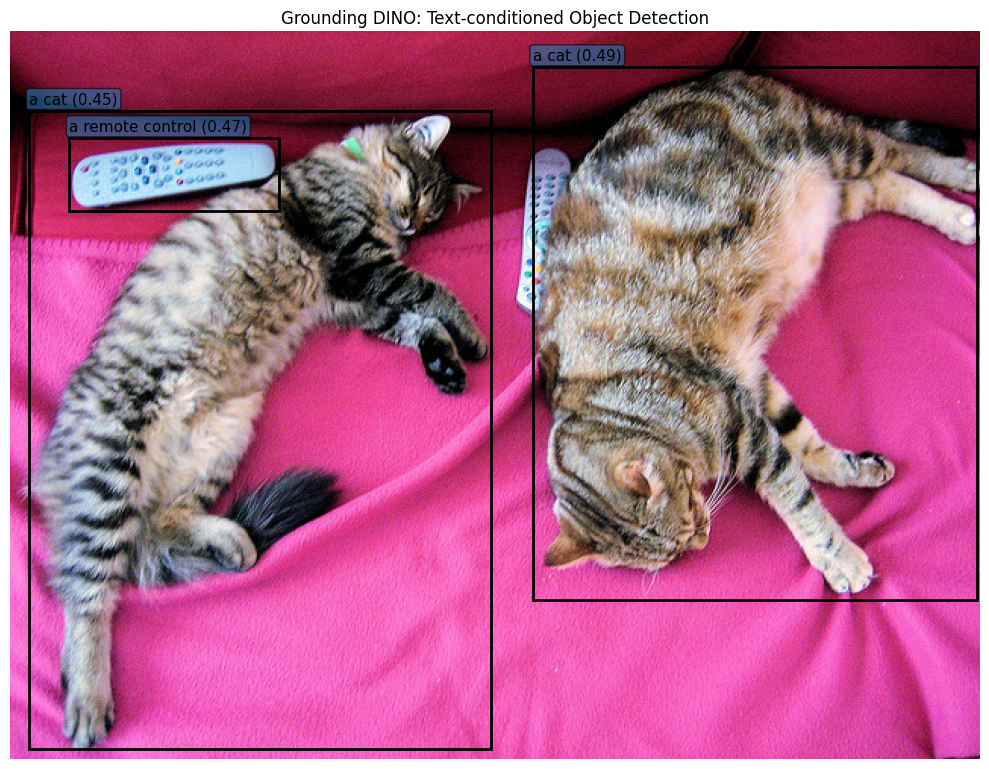

In [24]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(image)

detected_labels = result.get("text_labels", result.get("labels"))

for score, box, label in zip(
    result["scores"].detach().cpu(),
    result["boxes"].detach().cpu(),
    detected_labels
):
    x1, y1, x2, y2 = box.tolist()

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        fill=False
    )
    ax.add_patch(rect)

    ax.text(
        x1,
        max(0, y1 - 5),
        f"{label} ({score.item():.2f})",
        fontsize=11,
        bbox=dict(alpha=0.6, boxstyle="round,pad=0.2")
    )

ax.axis("off")
ax.set_title("Grounding DINO: Text-conditioned Object Detection")
plt.tight_layout()
plt.show()

# **4. BLIP**
- CLIP은 이미지와 텍스트를 같은 임베딩 공간에 잘 정렬하지만 기본적으로 텍스트 생성 모델은 아님
- BLIP은 이미지-텍스트 정렬뿐 아니라 이미지 캡셔닝, 이미지-텍스트 매칭, VQA 같은 이해/생성 작업을 함께 다루는 방향으로 발전. 웹에서 모은 이미지-텍스트 쌍의 노이즈를 그대로 믿지 않고, 모델이 캡션을 생성하고 필터링하여 데이터를 개선하는 CapFit 방식
[논문](https://arxiv.org/pdf/2201.12086)

# BLIP 구조

BLIP은 하나의 Transformer 계열을 상황에 따라 다르게 사용해 아래와 같은 특징을 가지고 있음

- Image encoder: 이미지를 시각 특징으로 변환
- Text encoder: 텍스트를 읽고 이미지-텍스트 정렬/매칭에 활용
- Image-grounded text decoder: 이미지 특징을 cross-attention으로 보면서 다음 토큰을 생성  

In [25]:
print("image size (W,H):", image.size)
for idx, (box, score) in enumerate(zip(result["boxes"], result["scores"])):
    x1, y1, x2, y2 = [float(v) for v in box.cpu().tolist()]
    valid = (0 <= x1 <= x2 <= image.width) and (0 <= y1 <= y2 <= image.height)
    print(f"{idx}: score={float(score):.3f}, box={[round(x1), round(y1), round(x2), round(y2)]}, in_bounds={valid}")

image size (W,H): (640, 480)
0: score=0.487, box=[345, 23, 637, 375], in_bounds=True
1: score=0.451, box=[12, 52, 317, 473], in_bounds=True
2: score=0.466, box=[39, 70, 177, 118], in_bounds=True


- self-Attention: 같은 입력 내부의 참고
- cross-attention: 한 종류의 표현이 다른 종류의 표현을 참고. BLIP의 텍스트 생성기는 문장을 만들면서 이미지 특징을 cross-attention으로 바라볼 수 있음

In [26]:
import requests
import torch
from PIL import Image
from transformers import AutoProcessor, BlipForConditionalGeneration

BLIP_MODEL_ID = "Salesforce/blip-image-captioning-base"
processor = AutoProcessor.from_pretrained(BLIP_MODEL_ID)
model = BlipForConditionalGeneration.from_pretrained(BLIP_MODEL_ID).to(device)
model.eval()

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hurwa\.cache\huggingface\hub\models--Salesforce--blip-image-captioning-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  990MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

BlipForConditionalGeneration(
  (vision_model): BlipVisionModel(
    (embeddings): BlipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (encoder): BlipEncoder(
      (layers): ModuleList(
        (0-11): 12 x BlipEncoderLayer(
          (self_attn): BlipAttention(
            (dropout): Dropout(p=0.0, inplace=False)
            (qkv): Linear(in_features=768, out_features=2304, bias=True)
            (projection): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): BlipMLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        )
      )
    )
    (post_layernorm): Laye

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

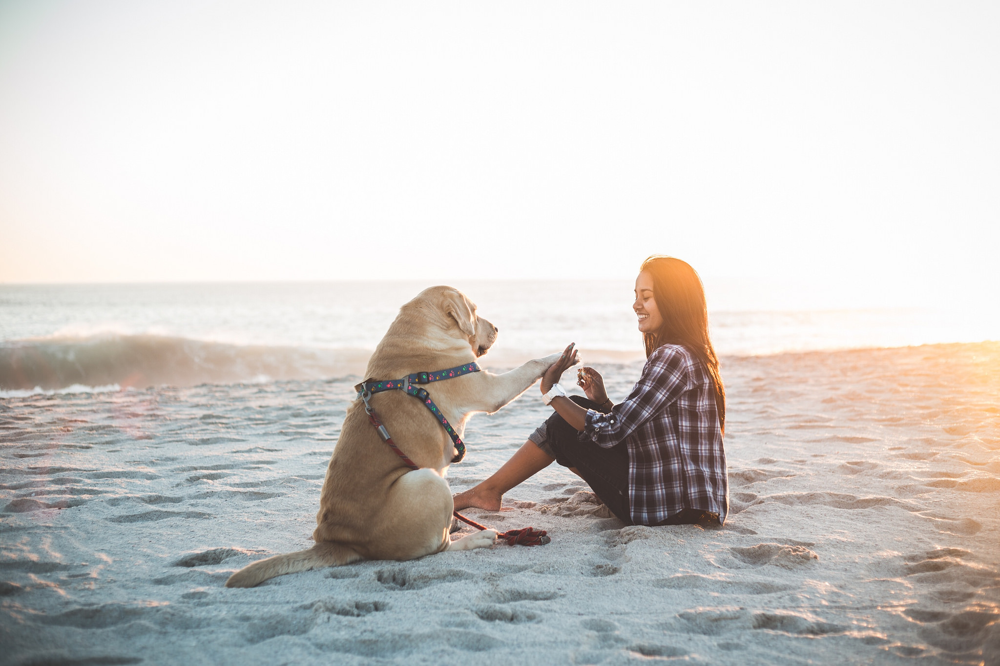

In [27]:
image_url = "https://storage.googleapis.com/sfr-vision-language-research/BLIP/demo.jpg"
image = Image.open(io.BytesIO(requests.get(image_url, timeout=30).content)).convert("RGB")
display(image)

In [28]:
inputs = processor(images=image, return_tensors="pt").to(device)

with torch.inference_mode():
    generated_ids = model.generate(**inputs, max_new_tokens=30)

caption = processor.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()
print("caption:", caption)

caption: a woman sitting on the beach with her dog


# 1. BLIP2의 배경

https://ryuzyproject.tistory.com/246

기존 Vision-Language 모델들의 문제점은 다음과 같습니다.

이미지 인코더 + 텍스트 인코더 + 멀티모달 인코더를 모두 새로 학습
학습 데이터 수억~수십억 개 필요
연산량이 매우 큼
LLM을 직접 멀티모달로 다시 학습해야 함
👉 BLIP-2는 “이미 잘 학습된 모델은 그대로 두고, 연결만 잘하자”라는 전략을 사용합니다.

### BLIP
- 시각, 언어 이해/생성 통합 학습
- 캡셔닝, VQA, Cross-Attention
- 이미지 특징을 활용해 텍스트 생성

### BLIP2
- 기존 비전 모델과 기존 LLM 연결
- Q-Former, Query Token, 동결된 모델
- 이미지 특징 > Q-Former -> 연결 계층 -> LLM

## Visiton Encoder
```
영상: 높이 * 너비 * 3(RGB)
예)
영상에서 256개 위치의 특징
영상 > Vision Encoder > [특징1 (1000개)] [특징2(1000개)] ... [특징256(1000개)]
```

위 특징들을 그대로 LLM에 넣을 수 없음
- 시각 특징과 언어 모델의 벡터 차원과 표현 공간이 다를 수 있음
- 모든 시각 특징을 그대로 전달하면 계산량과 입력 길이가 커짐
- 문장을 생성할 때 필요한 시각 정보가 무엇인지 선별하기 어려움

> BLIP-2는 이를 해결하기 위해 정해진 수의 학습 가능한 Query Token을 이용함. 대표적인 BLIP-2 설정은 32개의 Query Token을 사용

### 2. Q-Former

1. 이미지 특징을 준비
- Vision Encoder가 영상을 분석해 여러 특징을 만들어 둠.

2. Query Token 32개를 준비
- Q-Former 안에는 처음부터 학습 가능한 32개의 벡터가 있음.

4. Query끼리도 정보를 주고받기

Q-Former의 Self-Attention을 통해 Query간 정보를 교환. Cross-Attention은 이미지 특징을 참고, Self-Attention은 Query 표현들 사이의 관계를 계산.


5. LLM이 사용할 형태로 전달

Q-Former의 출력은 필요한 경우 Linear Projection을 거쳐 LLM의 임베딩 차원으로 변환. 이후 LLM이 이 정보를 조건으로 문장을 생성

> Q-Former는 이미지 전체를 "문장으로 번역"하는 것이 아니라, 이미지 특징에서 필요한 정보를 추출해 언어 모델과 연결하는 모듈임

### Query, Key, Value

BLIP-2 Q-Former의 이미지 Cross-Attention에서 개념적으로

- Q(Query): Q-Former의 Query 표현에서 생성
- K(Key): 이미지 인코더가 만든 시각 특징에서 생성
- V(Value): 이미지 인코더가 만든 시각 특징에서 생성

1. Q와 K의 내적: 어떤 이미지 특징을 얼마나 참고할지 점수를 계산
2. Softmax: 각 특징에 대한 참고 비중을 만듦
3. 가중치 * V: 시각 특징들을 가중합해 Query 출력을 업데이트

In [ ]:
import torch
import torch.nn.functional as F

# 3개 이미지 위치가 가진 특징(각 위치마다 2개 숫자)
image_keys = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
image_values = torch.tensor([[10., 0.], [0., 20.], [10., 20.]])
query = torch.tensor([[1., 0.]])

#??
scores = (query @ image_keys.T) / (image_keys.shape[-1] ** 0.5)
weights = F.softmax(scores, dim=-1)
summary = weights @ image_values

print('이미지 특징별 attention 점수: ', scores.round(decimals=3))
print('참고 비중: ', weights.round(decimals=3))
print('가중합 결과: ', summary.round(decimals=3))

이미지 특징별 attention 점수:  tensor([[0.7070, 0.0000, 0.7070]])
참고 비중:  tensor([[0.4010, 0.1980, 0.4010]])
가중합 결과:  tensor([[ 8.0220, 11.9780]])


In [8]:
import torch
from PIL import Image
from io import BytesIO
import requests
from transformers import Blip2Processor, Blip2ForConditionalGeneration
DEVICE="cuda"
BLIP2_MODEL_ID = "Salesforce/blip2-opt-2.7b"
blip2_dtype = torch.float16 if DEVICE == "cuda" else torch.float32

# blip2는 이미지와 텍스트를 함께 입력받을 수 있음(두 종류의 전처리가 필요)
# 이미지: 이미지 크기 조정. RGB 이미지 처리. 픽셀 값을 텐서로 변환. 정규화 수행
# 텍스트: Tokenizer를 이용해 토큰 ID로 변환.
blip2_processor = Blip2Processor.from_pretrained(BLIP2_MODEL_ID)
# Blip2ForConditionalGeneration: 모델 클래스. 이미지나 질문 등의 입력을 조건으로 텍스트를 생성
blip2_model = Blip2ForConditionalGeneration.from_pretrained(
    BLIP2_MODEL_ID, torch_dtype=blip2_dtype
).to(DEVICE)
blip2_model.eval()
print("BLIP-2 device:", DEVICE)

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hurwa\.cache\huggingface\hub\models--Salesforce--blip2-opt-2.7b. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


preprocessor_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/882 [00:00<?, ?B/s]

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hurwa\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/1247 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

BLIP-2 device: cuda


### 모델 양자화
- 모델이 사용하는 숫자의 정밀도를 낮춰서 메모리 사용량을 줄이고, 경우에 따라 추론 속도를 높이는 기술
- 예) FP16으로 저장된 가중치를 INT8이나 4비트 형태로 바꾸면 더 적은 메모리로 모델을 실행

```
weights = [0.123456, -0.123456, 0.5678843]

파라미터가 70억 개 있는 모델의 경우
FP32: 32비트/4바이트 > 28GB
FP16: 16비트/2바이트 > 14GB
INT8: 8비트/1바이트 > 7GB
INT4: 4비트/0.5바이트 > 3.5GB

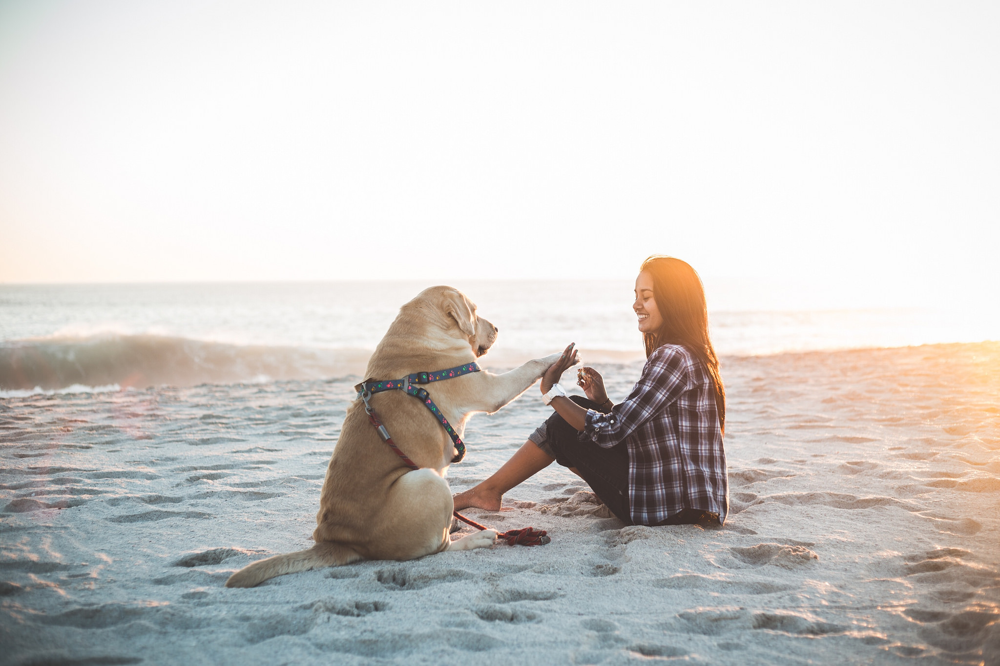

이미지 크기: (2048, 1365)


In [10]:
blip2_url = "https://storage.googleapis.com/sfr-vision-language-research/BLIP/demo.jpg"
blip2_resp = requests.get(blip2_url, timeout=30)
blip2_resp.raise_for_status()
blip2_image = Image.open(BytesIO(blip2_resp.content)).convert("RGB")
display(blip2_image)
print("이미지 크기:", blip2_image.size)

In [11]:
blip2_caption_inputs = blip2_processor(images=blip2_image, return_tensors="pt").to(
    DEVICE, blip2_dtype
)
with torch.inference_mode():
    blip2_caption_ids = blip2_model.generate(
        **blip2_caption_inputs,
        max_new_tokens=35,
        do_sample=False,
    )
print("캡셔닝:", blip2_processor.batch_decode(blip2_caption_ids, skip_special_tokens=True)[0].strip())

캡셔닝: a woman sitting on the beach with a dog


### VQA
- Visual Question Answering
- 이미지와 질문을 함께 입력하여 답변을 생성하는 작업
- BLIP-2 OPT 모델은 영어 질문을 우선 사용
- Salesforce/blip2-opt-2.7b는 VQA 전용으로 최적화된 모델이 아니므로, 질문 형식에 따라 엉뚱한 답을 할 수 있음


In [12]:
def ask_blip2(question, image=blip2_image, max_new_tokens=30):
    prompt = f"Question: {question} Answer:"
    inputs = blip2_processor(images=image, text=prompt, return_tensors="pt").to(
        DEVICE, blip2_dtype
    )
    with torch.inference_mode():
        ids = blip2_model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False,
            num_beams=3
        )
    decoded = blip2_processor.batch_decode(ids, skip_special_tokens=True)[0].strip()
    if decoded.startswith(prompt):
        decoded = decoded[len(prompt):].strip()
    return decoded

questions = [
    "What animal is in the picture?",
    "Where is the dog sitting?",
    "What color is the dog?",
]
for question in questions:
    print("질문:", question)
    print("답변:", ask_blip2(question))
    print("-" * 50)

질문: What animal is in the picture?
답변: Labrador Retriever
--------------------------------------------------
질문: Where is the dog sitting?
답변: The dog is sitting on the beach
--------------------------------------------------
질문: What color is the dog?
답변: The dog is the color of the sky
--------------------------------------------------


In [13]:
print("Q-Former 클래스:", type(blip2_model.qformer).__name__)
print("Query Token 텐서 크기:", tuple(blip2_model.query_tokens.shape))
print("Query Token 개수:", blip2_model.query_tokens.shape[1])
print("Q-Former hidden size:", blip2_model.config.qformer_config.hidden_size)
print("Vision hidden size:", blip2_model.config.vision_config.hidden_size)
print("LLM hidden size:", blip2_model.config.text_config.hidden_size)
print("연결 계층:", blip2_model.language_projection)

Q-Former 클래스: Blip2QFormerModel
Query Token 텐서 크기: (1, 32, 768)
Query Token 개수: 32
Q-Former hidden size: 768
Vision hidden size: 1408
LLM hidden size: 2560
연결 계층: Linear(in_features=768, out_features=2560, bias=True)
